#**Download dataset**


In [ ]:
!pip install kaggle

In [ ]:
mkdir -p ~/.kaggle && echo KGAT_635c74122945ce6bc69c3799e26d0a8f > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token

In [ ]:
!kaggle datasets download -d jangedoo/utkface-new
!unzip -q utkface-new.zip -d utkface

Dataset URL: https://www.kaggle.com/datasets/jangedoo/utkface-new
License(s): copyright-authors
100% 331M/331M [00:16<00:00, 21.3MB/s]



#**Preprocessing**


In [ ]:
from PIL import Image
import os
import torch
import numpy as np

folder = "utkface/UTKFace"
filenames = os.listdir(folder)
filepaths = [os.path.join(folder,f) for f in filenames]
images = [np.array(Image.open(f).resize((224,224)).convert("RGB")) for f in filepaths]

In [ ]:
images = np.stack(images)
images = torch.tensor(images)
images = images.permute(0,3,1,2)
images.shape

torch.Size([23708, 3, 224, 224])

In [ ]:
labels = [int(f.split('_')[0]) for f in filenames]
labels = torch.tensor(labels, dtype=torch.float32)
labels = torch.where(labels>80,80,labels)
labels_nor = labels / labels.max()


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    images, labels_nor,
    test_size = 0.2,
    random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_val, y_val,
    test_size = 0.2,
    random_state=42
)


In [ ]:
from torch.utils.data import WeightedRandomSampler

bins = np.linspace(y_train.min(), y_train.max(), 30)
bin_idx = np.digitize(y_train, bins)
bin_counts = np.bincount(bin_idx)
bin_counts[bin_counts == 0] = 1
sample_weights = 1.0 / bin_counts[bin_idx]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)


#**DataLoader**


In [ ]:
from torch.utils.data import Dataset, DataLoader

class Age_dataset(Dataset):
    def __init__(self,images,labels):
        self.images = images
        self.labels = labels

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx].float() / 255.0
        return img, self.labels[idx]

train_dataset = Age_dataset(X_train,y_train)
val_dataset = Age_dataset(X_val,y_val)

train_loader = DataLoader(train_dataset, batch_size=32,num_workers=2, pin_memory=True, sampler=sampler)
val_loader = DataLoader(val_dataset, batch_size=32,num_workers=2, pin_memory=True,shuffle=True)


#**Model**


In [ ]:
from torchvision import models


weights = models.ResNet18_Weights.DEFAULT
resnet_model = models.resnet18(weights=weights)

for param in resnet_model.parameters():
    param.requires_grad = False

for param in resnet_model.layer4.parameters():
    param.requires_grad = True


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


In [ ]:
import torch.nn as nn

class Age_model_Resnet(nn.Module):
    def __init__(self, pretrained_model):
        super().__init__()
        pretrained_model.fc = nn.Identity()
        self.pretrain_layer = pretrained_model
        self.fc = nn.Sequential(
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 1)
        )
    def forward(self,x):
        x = self.pretrain_layer(x)
        x = self.fc(x)
        return x

image1, label1 = train_dataset[:2]
model_test = Age_model_Resnet(pretrained_model=resnet_model)
model_test(image1).shape


torch.Size([2, 1])

#**Training**


In [ ]:
from tqdm import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_train = Age_model_Resnet(pretrained_model=resnet_model)
model = model_train.to(device)

criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)

num_epochs = 20
history = {"Train":[],'Val':[]}
for epoch in tqdm(range((num_epochs))):
    total_loss = 0
    model.train()
    for X, y in train_loader:
        X, y = X.to(device), y.to(device).view(-1,1)
        predict = model(X)
        loss = criterion(predict, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(X)
    epoch_loss = total_loss / len(train_dataset)
    history["Train"].append(epoch_loss)

    model.eval()
    val_total = 0
    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.to(device).view(-1,1)
            predict = model(X)
            loss = criterion(predict, y)



            val_total += loss.item() * len(X)
        epoch_loss = val_total / len(val_dataset)
        history["Val"].append(epoch_loss)







100%|██████████| 20/20 [11:42<00:00, 35.14s/it]


#**Evaluate**


In [ ]:
import plotly.graph_objects as go

fig = go.Figure(data=[go.Scatter(y=history['Train'],mode='lines',name='Train loss'),
                      go.Scatter(y=history['Val'],mode='lines',name='Val loss')])
fig.show()



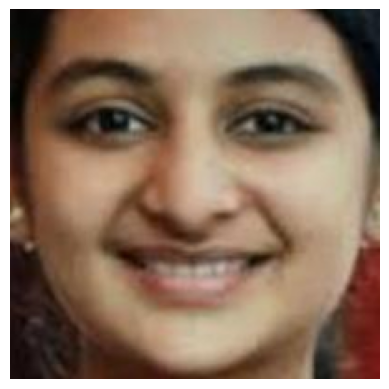

tensor(17.5325) tensor(22.)


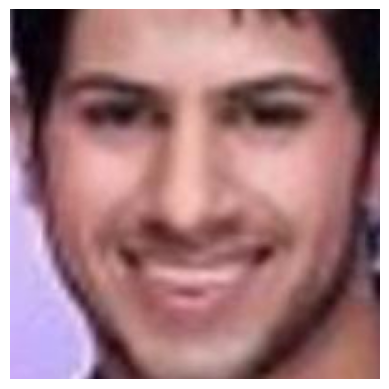

tensor(21.8844) tensor(26.)


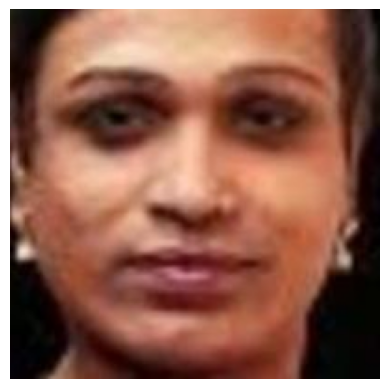

tensor(29.6933) tensor(47.)


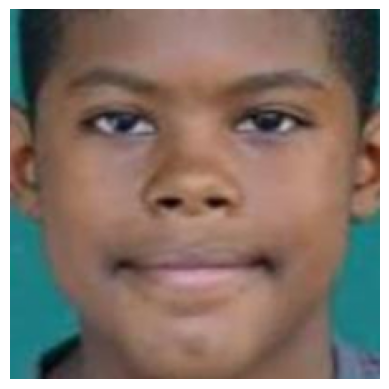

tensor(11.6157) tensor(14.)


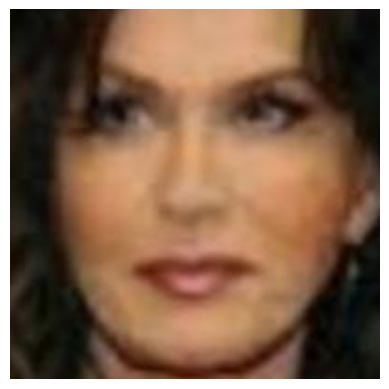

tensor(29.8037) tensor(35.)


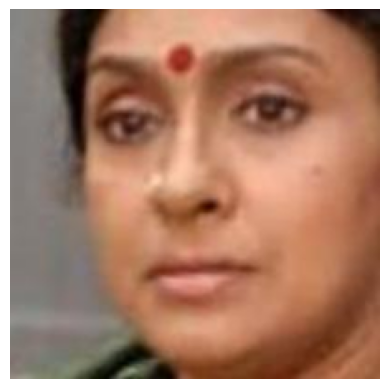

tensor(28.3537) tensor(51.)


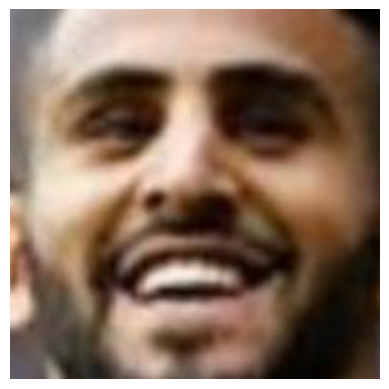

tensor(32.3627) tensor(27.)


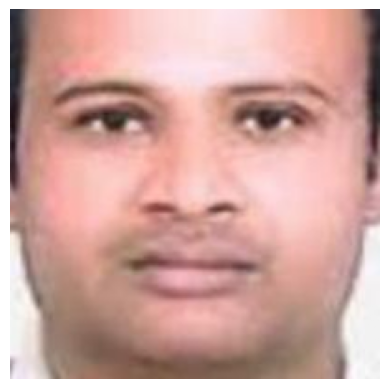

tensor(21.6823) tensor(28.)


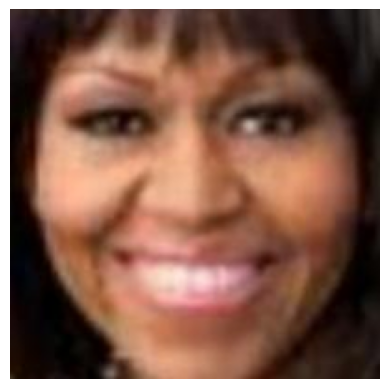

tensor(39.4950) tensor(54.)


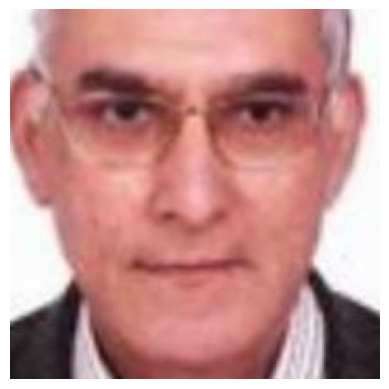

tensor(55.5050) tensor(58.)


In [ ]:
import matplotlib.pyplot as plt
test_dataset = Age_dataset(X_test, y_test)

model.eval()
for i in range(10,20):
    with torch.no_grad():
        X, y = test_dataset[i]
        image_for_test = X.permute(1, 2, 0).numpy()

        plt.imshow(image_for_test)
        plt.axis("off")
        plt.show()

        X, y = X.to(device), y.to(device)
        y_pred = model(X.unsqueeze(0))
        print(y_pred.item() * labels.max(), y.item() * labels.max())


In [ ]:
torch.save(model.state_dict(), "resnet_model.pth")